📁 Target file verified: 'lenta_north_korea.xlsx'
Loaded North Korea articles: 77 cases
Preprocessing in progress...
Preprocessed file saved: preprocessed_lenta_north_korea.xlsx
📌 TOP KEYWORDS DOCUMENT FREQUENCY ANALYSIS BY 4 CATEGORIES (TOP 10)

🔹 [< Category: Names >]
Names Keyword (Lemma)  Article Count
           ким_чен_ын             54
       владимир_путин             15
        дональд_трамп              9
               хвасон              7
              дмитрий              7
             вячеслав              6
             медведев              6
        сергей_лавров              5
           ли_чжэ_мён              5
              володин              5

🔹 [< Category: Countries/Geographies >]
Countries/Geographies Keyword (Lemma)  Article Count
                                  сша             20
                              украина              9
                               москва              8
                                китай              7
                 

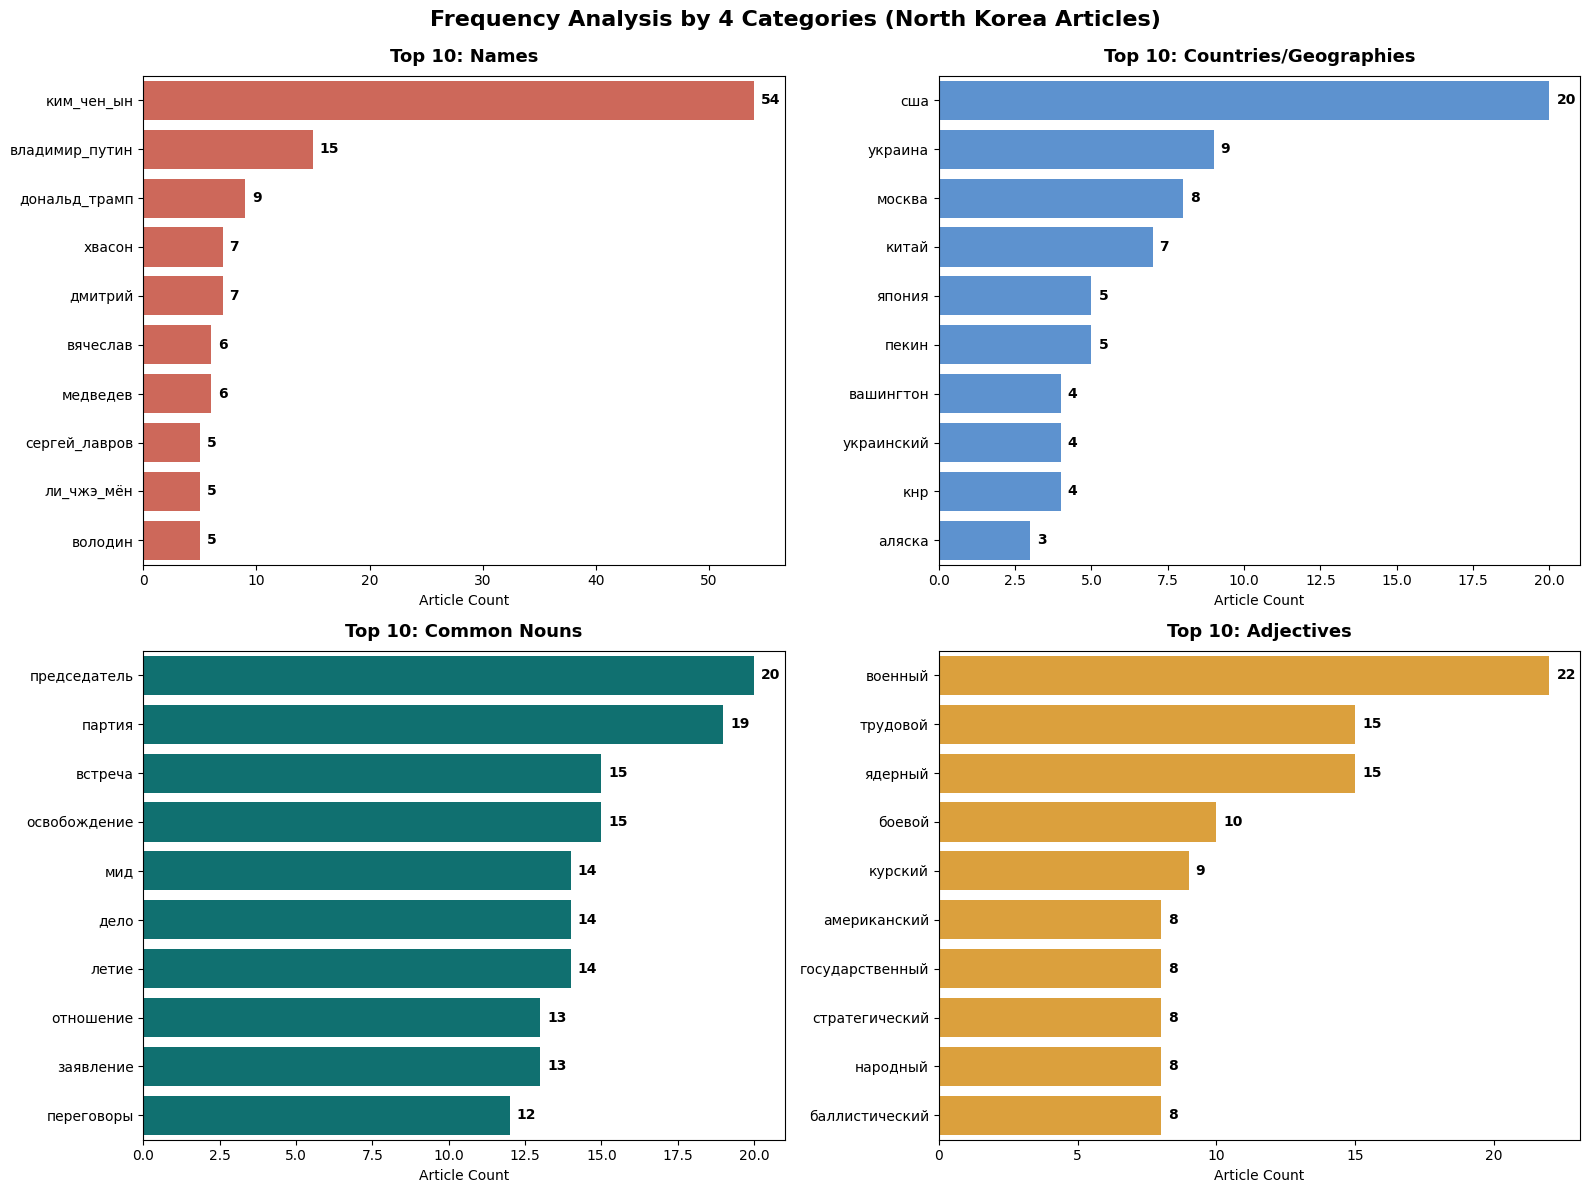

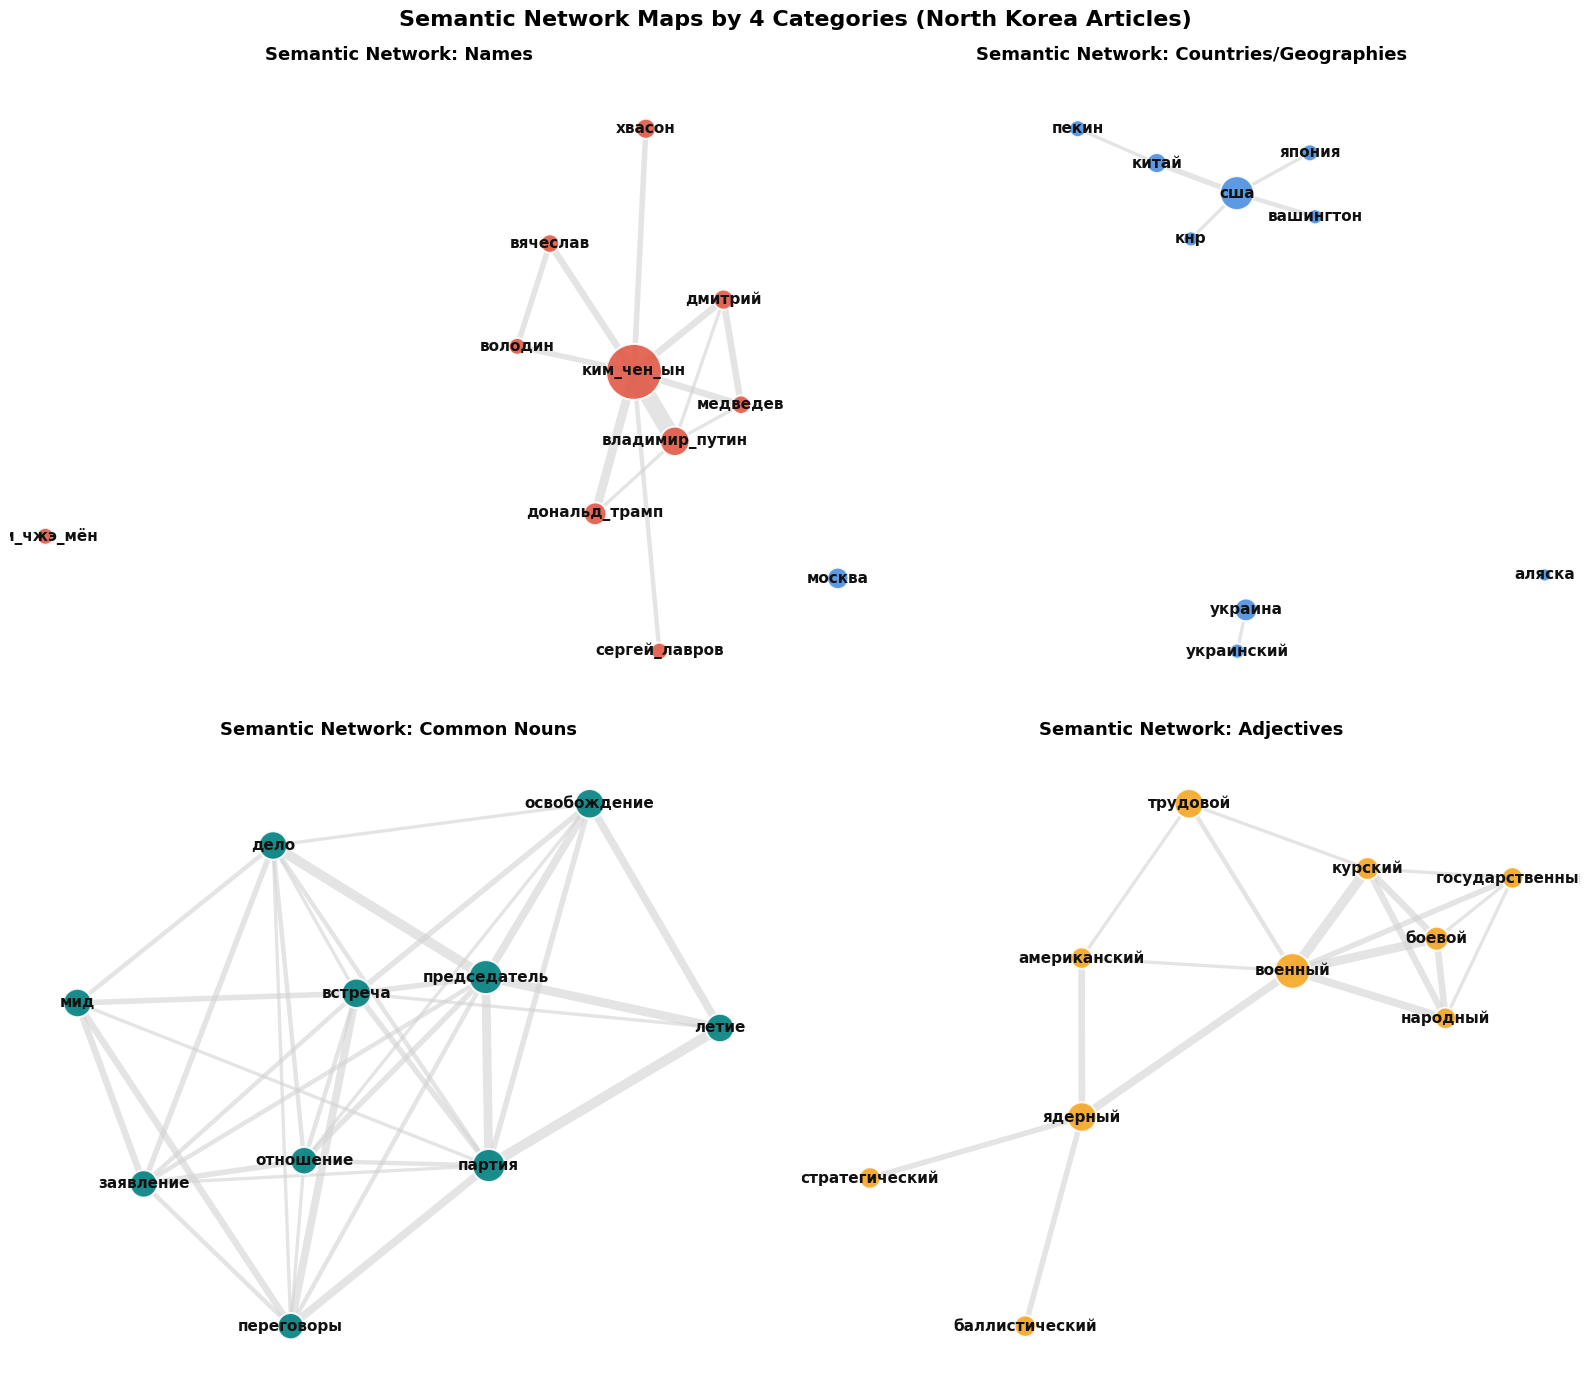

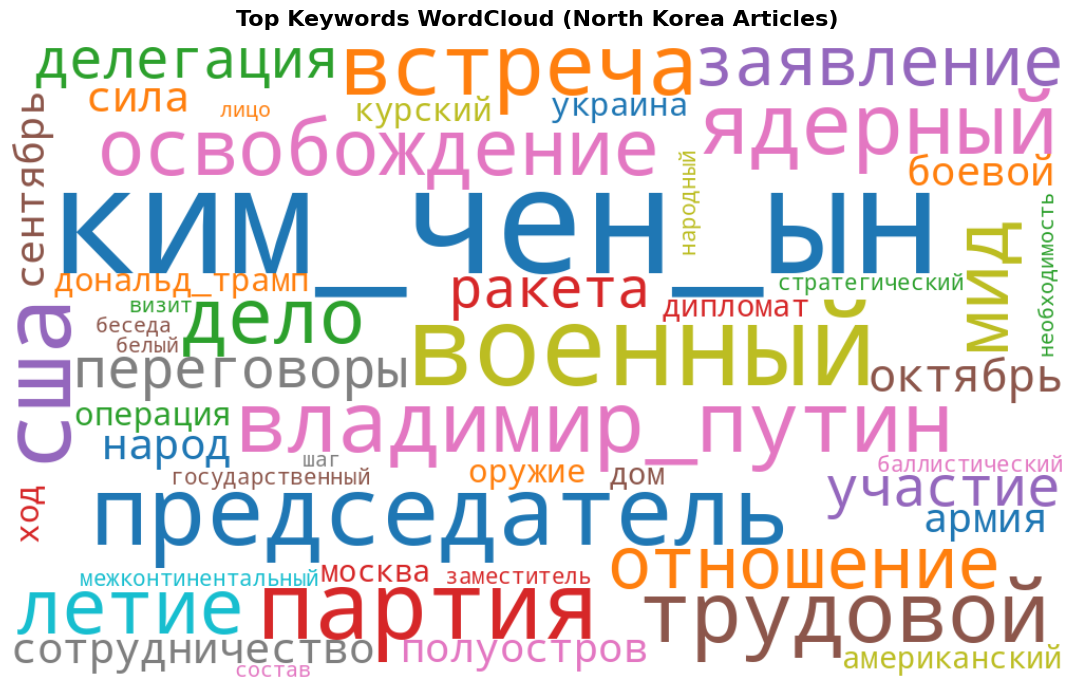


🎉 조선중앙통신(ЦТАК) 불용어가 완벽히 반영된 최종 분석 작업이 완료되었습니다!


In [7]:
# ==========================================
# 1. 필요 라이브러리 설치 및 불러오기
# ==========================================
!pip install pandas openpyxl pymorphy3 pymorphy3-dicts-ru nltk networkx matplotlib seaborn wordcloud > /dev/null 2>&1

import os
import glob
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import networkx as nx
from itertools import combinations
import pymorphy3
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud

# 코랩 폰트 및 다국어 설정 (러시아어 깨짐 방지)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

nltk.download('stopwords', quiet=True)

# ==========================================
# 2. 원본 데이터 불러오기 (lenta_north_korea.xlsx)
# ==========================================
target_file = 'lenta_north_korea.xlsx'

if os.path.exists(target_file):
    file_path = target_file
    print(f"📁 Target file verified: '{file_path}'")
else:
    xlsx_files = glob.glob("*.xlsx")
    if xlsx_files:
        file_path = xlsx_files[0]
        print(f"💡 Detected Excel file: '{file_path}'")
    else:
        raise FileNotFoundError("❌ Please upload Excel file to Colab file section.")

# 북한 기사 전용 데이터 로드
df = pd.read_excel(file_path)
df_filtered = df.copy()
print(f"Loaded North Korea articles: {len(df_filtered)} cases")

# ==========================================
# 3. 불용어 및 인명 단일화 정밀 처리 (조선중앙통신 불용어 추가)
# ==========================================
morph = pymorphy3.MorphAnalyzer()
ru_stopwords = set(stopwords.words('russian'))

custom_stopwords = {
    'imdb',
    'страна', 'государство', 'республика',
    'корея', 'южный', 'северный', 'корейский', 'южнокорейский', 'северокорейский',
    'сеул', 'пхеньян', 'россия', 'российский', 'кндр',
    'настоящий', 'расположенный', 'находящийся', 'местный', 'региональный',
    'мировой', 'международный', 'восток', 'запад',
    'город', 'место', 'район', 'часть', 'сторона', 'центр', 'область', 'территория',
    'событие', 'случай', 'итог', 'когда', 'уровень', 'число', 'количество', 'вид',
    'вопрос', 'проблема', 'связь', 'ситуация', 'служба', 'компания', 'организация',
    'заявить', 'сообщить', 'отметить', 'рассказать', 'добавить', 'пояснить', 'сказать',
    'президент', 'глава', 'министр', 'представитель', 'лидер', 'чиновник',
    'год', 'день', 'время', 'человек', 'минута', 'месяц', 'час', 'неделя',
    'слово', 'сообщение', 'издание', 'новости', 'риа', 'лента', 'ру', 'информация', 'данные',
    'тысяча', 'миллион', 'миллиард', 'один', 'два', 'три', 'первый', 'второй', 'третий',
    'который', 'свой', 'это', 'также', 'весь', 'он', 'она', 'они', 'наш', 'ваш', 'такой',
    'самый', 'новый', 'главный', 'другой', 'каждый', 'хороший', 'большой', 'высокий',
    'прошлый', 'следующий', 'последний', 'разный', 'многие', 'некоторый', 'любой', 'целый',
    # 조선중앙통신 관련 불용어 키워드 추가
    'цтак', 'цтака', 'цтаку', 'цтаком', 'цтаке', 'центральный', 'телеграфный', 'агентство'
}

english_stopwords = {
    'daily', 'weekly', 'times', 'press', 'journal', 'post', 'herald', 'tribune',
    'youtube', 'air', 'the', 'and', 'for', 'with', 'from', 'in', 'on', 'at', 'to', 'of', 'by',
    'tv', 'video', 'media', 'news', 'online', 'social', 'app', 'site', 'web', 'page', 'com',
    'net', 'org', 'info', 'live', 'channel', 'official', 'pro', 'max', 'mini', 'kcna'
}

full_stopwords = ru_stopwords.union(custom_stopwords).union(english_stopwords)
country_geo_keywords = {'вашингтон', 'москва', 'пекин', 'токио', 'сеул', 'украина'}

def replace_names_bulletproof(text):
    if not isinstance(text, str):
        return ""

    text = text.lower()

    if 'об этом сообщает' in text:
        text = text.split('об этом сообщает')[0]
    if 'об этом пишет' in text:
        text = text.split('об этом пишет')[0]

    # 1. 블라디미르 푸틴 (풀네임 및 성 단독/격변화 전체 일통)
    text = re.sub(r'\b(владимир|владимира|владимиру|владимиром|владимире)?\s*(путин|путина|путину|путиным|путине)\b', 'владимир_путин', text)

    # 2. 도날드 트럼프 (풀네임 및 성 단독/격변화 전체 일통)
    text = re.sub(r'\b(доналдьд|дональд|дональда|дональду|дональдом)?\s*(трамп|трампа|трампу|трампом|трампе)\b', 'дональд_трамп', text)

    # 3. 시진핑 (격변화 패턴 포함)
    text = re.sub(r'\b(си\s+)?цзиньпин[а-яё]*\b', 'си_цзиньпин', text)

    # 4. 기타 주요 외국 인물
    text = re.sub(r'\b(джо\s+)?байден[а-яё]*\b', 'джо_байден', text)
    text = re.sub(r'\b(владимир\s+)?зеленский[а-яё]*\b', 'владимир_зеленский', text)
    text = re.sub(r'\b(сергей\s+)?лавров[а-яё]*\b', 'сергей_лавров', text)

    # 5. 북한 및 한국 주요 인명 단일화
    korean_names = [
        (r'\bким\s+чен\s+ын[а-яё]*\b', 'ким_чен_ын'),
        (r'\bким\s+чжэн\s+ын[а-яё]*\b', 'ким_чен_ын'),
        (r'\bким\s+ё\s+чжон[а-яё]*\b', 'ким_ё_чжон'),
        (r'\bким\s+чен\s+ир[а-яё]*\b', 'ким_чен_ир'),
        (r'\bким\s+иль\s+сен[а-яё]*\b', 'ким_иль_сен'),
        (r'\bюн\s+сок\s+ёль[а-яё]*\b', 'юн_сок_ёль'),
        (r'\bли\s+чжэ\s+мён[а-яё]*\b', 'ли_чжэ_мён'),
        (r'\bмун\s+чжэ\s+ин[а-яё]*\b', 'мун_чжэ_ин')
    ]
    for pattern, repl in korean_names:
        text = re.sub(pattern, repl, text)

    # 중복 결합어 정돈
    text = re.sub(r'\b(владимир_путин\s*)+', 'владимир_путин ', text)
    text = re.sub(r'\b(дональд_трамп\s*)+', 'дональд_трамп ', text)
    text = re.sub(r'\b(си_цзиньпин\s*)+', 'си_цзиньпин ', text)
    text = re.sub(r'\b(ким_чен_ын\s*)+', 'ким_чен_ын ', text)

    return text.strip()

def preprocess_text_categorized(text):
    if not isinstance(text, str):
        return [], ""

    text_replaced = replace_names_bulletproof(text)
    raw_words = re.findall(r'[а-яа-яёëa-za-z_]+', text_replaced.lower())

    categorized_tuples = []
    clean_words = []
    i = 0
    n = len(raw_words)

    korean_surnames = {'ким', 'юн', 'ли', 'пак', 'мун', 'сон', 'чхве', 'чо', 'чжо', 'кан', 'хан', 'чон', 'чжин', 'чжу', 'чжи', 'но', 'син', '안', 'пон'}

    while i < n:
        word = raw_words[i]

        # 1. 이미 언더바(_)로 치환된 인명은 그대로 Names 카테고리에 고정
        if '_' in word:
            categorized_tuples.append((word, 'Names'))
            clean_words.append(word)
            i += 1
            continue

        # 2. 순수 영단어 제외
        if word.isalpha() and all(ord(c) < 128 for c in word):
            i += 1
            continue

        parsed = morph.parse(word)[0]
        lemma = parsed.normal_form
        pos = parsed.tag.POS
        grammemes = parsed.tag.grammemes

        # 불용어 제외 (원형 및 원단어 모두 검사)
        if lemma in full_stopwords or word in full_stopwords or len(lemma) <= 2:
            i += 1
            continue

        # 3. 한국/북한 성씨 자동 결합 (성 + 이름)
        if lemma in korean_surnames and i + 1 < n:
            next_word = raw_words[i+1]
            next_lemma = morph.parse(next_word)[0].normal_form
            if i + 2 < n:
                third_word = raw_words[i+2]
                third_lemma = morph.parse(third_word)[0].normal_form
                if len(next_lemma) <= 8 and len(third_lemma) <= 8 and '_' not in next_lemma:
                    full_name = f"{lemma}_{next_lemma}_{third_lemma}"
                    categorized_tuples.append((full_name, 'Names'))
                    clean_words.append(full_name)
                    i += 3
                    continue
            if len(next_lemma) <= 10 and '_' not in next_lemma:
                full_name = f"{lemma}_{next_lemma}"
                categorized_tuples.append((full_name, 'Names'))
                clean_words.append(full_name)
                i += 2
                continue

        # 4. 품사 카테고리 분류
        is_name_tag = any(g in grammemes for g in ['Name', 'Surn', 'Patr'])
        is_non_noun_part = pos in ['ADJF', 'ADJS', 'ADVB', 'COMP', 'VERB', 'INFN', 'PRTF', 'PRTS', 'GRND', 'NUMR', 'PREP', 'CONJ', 'PRCL', 'INTJ']

        if is_name_tag and not is_non_noun_part:
            cat = 'Names'
        elif 'Geox' in grammemes or lemma in country_geo_keywords:
            cat = 'Countries/Geographies'
        elif pos in ['ADJF', 'ADJS']:
            cat = 'Adjectives'
        elif pos == 'NOUN':
            cat = 'Common Nouns'
        else:
            cat = 'Others'

        if cat != 'Others':
            categorized_tuples.append((lemma, cat))
            clean_words.append(lemma)

        i += 1

    return categorized_tuples, " ".join(clean_words)

print("Preprocessing in progress...")
results = (df_filtered['제목'].fillna('') + " " + df_filtered['본문'].fillna('')).apply(preprocess_text_categorized)
df_filtered['categorized_tuples'] = [res[0] for res in results]
df_filtered['clean_text_topic'] = [res[1] for res in results]

# ==========================================
# 4. 전처리 결과 저장
# ==========================================
preprocessed_excel = 'preprocessed_lenta_north_korea.xlsx'
df_filtered.drop(columns=['categorized_tuples']).to_excel(preprocessed_excel, index=False)
print(f"Preprocessed file saved: {preprocessed_excel}")

# ==========================================
# 5. 기사 단위 출현 빈도(Document Frequency) 집계 (Top 10)
# ==========================================
cat_counters = {
    'Names': Counter(),
    'Countries/Geographies': Counter(),
    'Common Nouns': Counter(),
    'Adjectives': Counter()
}

doc_unique_lemmas = []
for tuples in df_filtered['categorized_tuples']:
    unique_tuples_in_doc = list(set(tuples))
    doc_unique_lemmas.append(unique_tuples_in_doc)
    for word, cat in unique_tuples_in_doc:
        cat_counters[cat][word] += 1

all_unique_tuples = [item for doc in doc_unique_lemmas for item in doc]
word_cats = {word: cat for word, cat in all_unique_tuples}
overall_word_doc_counts = Counter([word for word, cat in all_unique_tuples])

dfs_by_cat = {}
print("=" * 65)
print("📌 TOP KEYWORDS DOCUMENT FREQUENCY ANALYSIS BY 4 CATEGORIES (TOP 10)")
print("=" * 65)

for cat_name, counter in cat_counters.items():
    top_items = counter.most_common(10)
    df_cat = pd.DataFrame(top_items, columns=[f'{cat_name} Keyword (Lemma)', 'Article Count'])
    dfs_by_cat[cat_name] = df_cat
    print(f"\n🔹 [< Category: {cat_name} >]")
    print(df_cat.to_string(index=False))

# ==========================================
# 6. 동시출현 의미 네트워크 데이터 생성 (4개 카테고리별 분리)
# ==========================================
graphs_by_cat = {}
threshold = 3

for cat_name, counter in cat_counters.items():
    top_keywords_cat = [word for word, count in counter.most_common(10)]
    co_matrix_cat = pd.DataFrame(0, index=top_keywords_cat, columns=top_keywords_cat)

    for doc_tuples in doc_unique_lemmas:
        lemmas_in_doc = list(set([w for w, c in doc_tuples if w in top_keywords_cat and c == cat_name]))
        for w1, w2 in combinations(lemmas_in_doc, 2):
            co_matrix_cat.loc[w1, w2] += 1
            co_matrix_cat.loc[w2, w1] += 1

    G_cat = nx.Graph()
    for word in top_keywords_cat:
        G_cat.add_node(word, frequency=int(counter[word]), category=cat_name)

    for i in range(len(top_keywords_cat)):
        for j in range(i + 1, len(top_keywords_cat)):
            w1, w2 = top_keywords_cat[i], top_keywords_cat[j]
            w_val = int(co_matrix_cat.loc[w1, w2])
            if w_val >= threshold:
                G_cat.add_edge(w1, w2, weight=w_val)

    graphs_by_cat[cat_name] = G_cat

# ==========================================
# 7. 시각 자료 출력 (막대 차트 + 카테고리별 네트워크 지도 + 워드클라우드)
# ==========================================
colors = {
    'Names': '#E05A47',
    'Countries/Geographies': '#4A90E2',
    'Common Nouns': '#008080',
    'Adjectives': '#F5A623'
}

# 1) 막대 그래프 (Top 10)
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, (cat_name, df_cat) in enumerate(dfs_by_cat.items()):
    ax = axes[idx]
    if not df_cat.empty:
        bars = sns.barplot(
            data=df_cat,
            x='Article Count',
            y=f'{cat_name} Keyword (Lemma)',
            ax=ax,
            color=colors.get(cat_name, '#008080'),
            orient='h'
        )
        for p in bars.patches:
            width = p.get_width()
            if width > 0:
                ax.annotate(
                    f'{int(width)}',
                    (width, p.get_y() + p.get_height() / 2.),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=10, fontweight='bold'
                )
        ax.set_title(f"Top 10: {cat_name}", fontsize=13, pad=10, fontweight='bold')
        ax.set_xlabel('Article Count')
        ax.set_ylabel('')

plt.suptitle("Frequency Analysis by 4 Categories (North Korea Articles)", fontsize=16, y=0.99, fontweight='bold')
plt.tight_layout()
plt.savefig('frequency_analysis_chart_north_korea.png', dpi=300, bbox_inches='tight')
plt.show()

# 2) 네트워크 지도 (4개 카테고리별)
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
axes = axes.flatten()

for idx, (cat_name, G_cat) in enumerate(graphs_by_cat.items()):
    ax = axes[idx]
    if G_cat.number_of_nodes() > 0:
        pos = nx.spring_layout(G_cat, k=0.6, seed=42, iterations=60)
        cat_color = colors.get(cat_name, '#008080')
        node_sizes = [int(G_cat.nodes[node].get('frequency', 1)) * 30 for node in G_cat.nodes()]
        edges = G_cat.edges()
        weights = [int(G_cat[u][v]['weight']) * 0.8 for u, v in edges] if len(edges) > 0 else []

        if len(edges) > 0:
            nx.draw_networkx_edges(G_cat, pos, ax=ax, width=weights, edge_color='#D3D3D3', alpha=0.6)

        nx.draw_networkx_nodes(G_cat, pos, ax=ax, node_size=node_sizes, node_color=cat_color, alpha=0.9, edgecolors='white', linewidths=1.5)
        nx.draw_networkx_labels(G_cat, pos, ax=ax, font_size=11, font_weight='bold', font_color='#111111')

    ax.set_title(f"Semantic Network: {cat_name}", fontsize=13, pad=10, fontweight='bold')
    ax.axis('off')

plt.suptitle("Semantic Network Maps by 4 Categories (North Korea Articles)", fontsize=16, y=0.99, fontweight='bold')
plt.tight_layout()
plt.savefig('semantic_network_map_north_korea.png', dpi=300, bbox_inches='tight')
plt.show()

# 3) 워드클라우드
wc_dict = dict(overall_word_doc_counts.most_common(50))
wordcloud = WordCloud(width=1000, height=600, background_color='white', colormap='tab10').generate_from_frequencies(wc_dict)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Top Keywords WordCloud (North Korea Articles)", fontsize=16, pad=15, fontweight='bold')
plt.tight_layout()
plt.savefig('wordcloud_analysis_north_korea.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n🎉 조선중앙통신(ЦТАК) 불용어가 완벽히 반영된 최종 분석 작업이 완료되었습니다!")